# Clean the metadata: deduplicated Subset data

Metadata is the information recorded alongside each image: age, sex and anatomical site. This notebook makes those records consistent without guessing missing details. Metadata cleaning preserves rows; a separate, frozen exact-image-copy audit then retains one image per identical-pixel group.

It reads only development source records and verifies the existing `dedup_v1` export for [02_clean_data_eda.ipynb](02_clean_data_eda.ipynb). It does not rewrite source files or access reserved-test records. Missing model fields receive `Unknown`. Diagnosis and the benign/malignant description remain for checks, but must be excluded from later model inputs because they reveal the outcome being predicted.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [01_data_cleaning.ipynb](../Subset/01_data_cleaning.ipynb).

Metadata-format cleaning is unchanged. Exact-copy retention, frozen-output verification and development-only source access are labelled adaptations of the original preparation stage.

## Setup

The setup uses the project root and names the development source and frozen output files in one place. The shared label check applies the original cleaning rule. The manifest and retention ledger define the population; this notebook checks their existing outputs rather than creating a new variant. The reserved-test source is not resolved or opened.

In [1]:
NOTEBOOK_STAGE = '01_data_cleaning'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from melanoma_detection.metadata_validation import validate_binary_target
from melanoma_detection.development_dataset import sha256_file
PROJECT_ROOT = ROOT
DATA_DIR = ROOT / "data/subset"
TRAIN_PATH = DATA_DIR / "train_labels.csv"
TRAIN_CLEAN_PATH = ROOT / "data/subset/processed/dedup_v1/train_folds.csv"
UNKNOWN_LABEL = "Unknown"
MODEL_FEATURES = ["sex", "age_approx", "anatom_site_general_challenge"]
LEAKAGE_COLUMNS = ["diagnosis", "benign_malignant", "target"]
ledger = context["ledger"]
original_ids = set(ledger.image_name)
retained_ids = set(data.image_name)
print(f"Data directory: {DATA_DIR}")
print(f"Frozen development output: {TRAIN_CLEAN_PATH}")
ORIGINAL_EXPORT_DPI = 150


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

Data directory: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset
Frozen development output: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\dedup_v1\train_folds.csv


## Load the source metadata

Each row represents an image. `image_name` identifies that image, while `patient_id` links images from the same person. The row and column counts below give us a starting point: metadata cleaning should not remove rows. Retention is an explicitly separate image-content decision: the original development source has 6,864 rows, of which 6,706 are retained for this report.

The target is the recorded outcome, where `0` means benign and `1` means malignant. We read it as text first so a bad value cannot be rounded into an apparently valid label.

In [2]:
# Inspect IDs first, then parse only audited development rows.
source_ids = pd.read_csv(TRAIN_PATH, usecols=["image_name"])["image_name"].tolist()
original_source = pd.read_csv(TRAIN_PATH, dtype={"target": "string"},
    skiprows=lambda number: number > 0 and source_ids[number - 1] not in original_ids)
assert set(original_source.image_name) == original_ids
train_raw = original_source.loc[original_source.image_name.isin(retained_ids)].copy()
train_raw = train_raw.sort_values("image_name").reset_index(drop=True)
print(f"Original development rows: {len(original_source):,}")
print(f"Retained training rows: {len(train_raw):,}; columns: {train_raw.shape[1]}")
print("Reserved-test data and labels: not loaded")

Original development rows: 6,864
Retained training rows: 6,706; columns: 8
Reserved-test data and labels: not loaded


## Check missing information

The table lists only columns with missing values. `missing_count` tells us how many image records lack that field; `missing_percent` divides that count by all rows in that file. A blank table means no missing values were found.

These tables show where cleaning is needed. A graph would add little here because we need the exact counts to check that the missing records are handled consistently.

The first table describes retained development records. The second is the original development comparison before exact-copy retention; neither table includes the reserved test.

In [3]:
def missing_profile(frame: pd.DataFrame) -> pd.DataFrame:
    missing_count = frame.isna().sum()
    return pd.DataFrame(
        {
            "missing_count": missing_count,
            "missing_percent": (100 * missing_count / len(frame)).round(3),
        }
    ).query("missing_count > 0")


print("Training missingness:")
print(missing_profile(train_raw).to_string())
print("\nOriginal development missingness (before retention):")
print(missing_profile(original_source).to_string())


Training missingness:
                               missing_count  missing_percent
anatom_site_general_challenge            195            2.908

Original development missingness (before retention):
                               missing_count  missing_percent
anatom_site_general_challenge            196            2.855


## Clean the values without guessing

Remove extra spaces, treat empty text as missing, and fill missing sex or site with `Unknown`. Keep age in its recorded five-year bucket, such as `45`; missing age also stays `Unknown`. Later models can choose a numeric representation using their training data.

Known ages must be numeric, between 0 and 120, and in five-year steps. These check the dataset's format, not clinical accuracy.

Validate the original target before integer conversion: only exact `0` and `1` are accepted. Reading labels as text prevents rounding from hiding an invalid value; converting `1.5` first, for example, would incorrectly turn it into `1`.


In [4]:
EXPECTED_SEX = {"female", "male", UNKNOWN_LABEL}
EXPECTED_SITES = {
    "head/neck",
    "lower extremity",
    "oral/genital",
    "palms/soles",
    "torso",
    "upper extremity",
    UNKNOWN_LABEL,
}


def strip_text_columns(frame: pd.DataFrame) -> pd.DataFrame:
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.eq(""), pd.NA)
    return cleaned


def clean_metadata(frame: pd.DataFrame) -> pd.DataFrame:
    cleaned = strip_text_columns(frame)

    required_columns = {
        "image_name",
        "patient_id",
        "sex",
        "age_approx",
        "anatom_site_general_challenge",
    }
    missing_columns = required_columns - set(cleaned.columns)
    if missing_columns:
        raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

    for column in ["sex", "anatom_site_general_challenge"]:
        cleaned[column] = cleaned[column].fillna(UNKNOWN_LABEL)

    age_numeric = pd.to_numeric(cleaned["age_approx"], errors="coerce")
    malformed_age = cleaned["age_approx"].notna() & age_numeric.isna()
    if malformed_age.any():
        bad_values = sorted(cleaned.loc[malformed_age, "age_approx"].unique())
        raise ValueError(f"Non-numeric age values found: {bad_values}")

    known_age = age_numeric.dropna()
    if not known_age.between(0, 120).all():
        raise ValueError("age_approx contains values outside the expected 0-120 range.")
    if not known_age.mod(5).eq(0).all():
        raise ValueError("age_approx contains values outside the expected five-year buckets.")

    cleaned["age_approx"] = age_numeric.map(
        lambda value: str(int(value)) if pd.notna(value) else UNKNOWN_LABEL
    )

    if "target" in cleaned.columns:
        cleaned["target"] = validate_binary_target(cleaned["target"])

    return cleaned


train_clean = clean_metadata(train_raw)
# Verify the frozen export rather than saving a new cleaning variant.
frozen_clean = data.drop(columns="fold").copy()
for column in [*MODEL_FEATURES, "image_name", "patient_id", "target"]:
    assert np.array_equal(train_clean[column].astype(str).to_numpy(),
                          frozen_clean[column].astype(str).to_numpy())


## Check the cleaned records

Check that row counts stay the same, image names are unique, patient identifiers are present, and feature values use the expected labels. The target must agree with the benign/malignant description.

`All validation checks passed` means these specific checks found no problem. Investigate a failed check before using the cleaned files.


The cleaned retained values must also match the frozen manifest export. Repeating the cleaning function in memory checks consistency; it does not replace the established cleaning artifact or alter a record.

In [5]:
def validate_common(frame: pd.DataFrame, source: pd.DataFrame, name: str) -> None:
    assert len(frame) == len(source), f"{name}: row count changed during cleaning."
    assert frame["image_name"].notna().all(), f"{name}: missing image_name."
    assert frame["patient_id"].notna().all(), f"{name}: missing patient_id."
    assert frame["image_name"].is_unique, f"{name}: duplicate image_name values."
    assert set(frame["sex"].unique()) <= EXPECTED_SEX, f"{name}: unexpected sex value."
    assert set(frame["anatom_site_general_challenge"].unique()) <= EXPECTED_SITES, (
        f"{name}: unexpected anatomical-site value."
    )
    assert frame[MODEL_FEATURES].isna().sum().sum() == 0, (
        f"{name}: model features still contain missing values."
    )


validate_common(train_clean, train_raw, "train")
# Reserved-test verification belongs to the later final-test stage.

assert set(train_clean["target"].unique()) <= {0, 1}, "Unexpected target value."
assert (
    ((train_clean["target"] == 1) & (train_clean["benign_malignant"] != "malignant"))
    | ((train_clean["target"] == 0) & (train_clean["benign_malignant"] != "benign"))
).sum() == 0, "target and benign_malignant disagree."

print("All validation checks passed.")


All validation checks passed.


### Read the change table

Compare `missing_before` with `unknown_after`: missing information should remain visible as an unknown category. `missing_after` should be zero for the three model fields. Filling a missing value changes how we store it; it does not recover the information.

Each row of this table describes one field in one development population. Use it to check the cleaning rule, rather than to judge model quality.

Compare original development with retained development to distinguish formatting changes from exact-copy removal. Retention removes one record with an unknown site, reducing that count from 196 to 195; it does not infer the missing location.

In [6]:
rows = []
for dataset_name, source, cleaned in [
    ("retained development", train_raw, train_clean),
    ("original development", original_source, clean_metadata(original_source)),
]:
    for column in MODEL_FEATURES:
        rows.append(
            {
                "dataset": dataset_name,
                "column": column,
                "missing_before": int(source[column].isna().sum()),
                "unknown_after": int(cleaned[column].eq(UNKNOWN_LABEL).sum()),
                "missing_after": int(cleaned[column].isna().sum()),
            }
        )

cleaning_summary = pd.DataFrame(rows)
print(cleaning_summary.to_string(index=False))


             dataset                        column  missing_before  unknown_after  missing_after
retained development                           sex               0              0              0
retained development                    age_approx               0              0              0
retained development anatom_site_general_challenge             195            195              0
original development                           sex               0              0              0
original development                    age_approx               0              0              0
original development anatom_site_general_challenge             196            196              0


## Verify the saved cleaned copies

The original cleaning stage saved copies in `data/subset/processed`. The deduplicated branch uses the separate frozen export in `data/subset/processed/dedup_v1/train_folds.csv`, with its manifest and retention ledger. The original files remain available so we can trace every retained or excluded record to its source.

**Scope adaptation:** this cell verifies the already saved output and its source hashes. Executing a documentation notebook does not write cleaned data, change retention decisions or modify the original branch.

In [7]:
# Verify the pre-existing manifest export; do not rewrite it.
saved_clean = pd.read_csv(TRAIN_CLEAN_PATH, dtype={"age_approx": "string"})
assert saved_clean.image_name.tolist() == data.image_name.tolist()
assert np.array_equal(saved_clean.target.to_numpy(), data.target.to_numpy())
assert saved_clean.patient_id.tolist() == data.patient_id.tolist()
assert np.array_equal(saved_clean.fold.to_numpy(), data.fold.to_numpy())
for relative, digest in context["manifest"]["audited_input_sha256"].items():
    assert sha256_file(ROOT / relative) == digest, "Audited source changed: " + relative
print(f"Verified existing frozen output: {TRAIN_CLEAN_PATH}")
print(f"Manifest SHA-256: {dataset_identity['dataset_manifest_sha256']}")
print("Source metadata and frozen data outputs were not rewritten.")

Verified existing frozen output: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\dedup_v1\train_folds.csv
Manifest SHA-256: 9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e177b7f6274dc71e3a1
Source metadata and frozen data outputs were not rewritten.


## Confirm exact copies and retain one deterministic representative

**Added deduplication audit.** A file SHA-256 identifies copies with identical bytes. The full-resolution decoded RGB fingerprint also detects identical pixels stored in different files. The audit compares all decoded pixels to confirm a candidate group; perceptual resemblance alone is insufficient. For each group, the lexicographically smallest image identifier is retained. Labels, model scores and performance never choose the representative.

Two different lesions can share age, sex and site, so identical metadata is not a reason to exclude them. The conflict check below verifies that confirmed groups agree on patient, target, fold and metadata. If a group had conflicting records, it would need investigation rather than an automatic merge. All original JPEGs remain on disk.

In [8]:
grouped = ledger.groupby("retained_image_name")
duplicates = grouped.filter(lambda rows: len(rows) > 1)
excluded = ledger.loc[ledger.decision.eq("excluded")]
group_checks = []
original_clean = pd.read_csv(ROOT / "data/subset/processed/train_clean.csv")
for representative, rows in duplicates.groupby("retained_image_name"):
    assert representative == min(rows.image_name)
    assert rows.pixel_sha256.nunique() == 1
    assert rows.patient_id.nunique() == rows.target.nunique() == rows.fold.nunique() == 1
    metadata_rows = original_clean.set_index("image_name").loc[rows.image_name, MODEL_FEATURES]
    assert metadata_rows.nunique(dropna=False).eq(1).all()
    assert rows.decision.eq("retained").sum() == 1
    group_checks.append({"representative": representative, "copies": len(rows),
        "patient": rows.patient_id.iloc[0], "label": rows.target.iloc[0],
        "file_hashes": rows.source_sha256.nunique()})
display(pd.DataFrame(group_checks).head(12))
display(pd.DataFrame([{"confirmed_groups": len(group_checks), "excluded": len(excluded),
    "excluded_benign": int(excluded.target.eq(0).sum()),
    "excluded_malignant": int(excluded.target.eq(1).sum())}]))
assert len(group_checks) == len(excluded) == 158

,representative,copies,patient,label,file_hashes
0,ISIC_0087297,2,IP_5389392,0,1
1,ISIC_0112097,2,IP_5889408,0,1
2,ISIC_0148783,2,IP_4488328,0,1
3,ISIC_0157530,2,IP_4488328,0,1
4,ISIC_0196945,2,IP_5389392,0,1
5,ISIC_0207209,2,IP_4488328,0,1
6,ISIC_0213336,2,IP_5889408,0,1
7,ISIC_0238002,2,IP_4488328,0,1
8,ISIC_0308133,2,IP_9422872,0,1
9,ISIC_0313653,2,IP_3751991,0,1


,confirmed_groups,excluded,excluded_benign,excluded_malignant
0,158,158,157,1


## Inspect an identical pair and a distinct review pair

The contact sheet provides a worked example of the retention rule. The top row is the first exact-copy group by image identifier. One is retained and one excluded because their full decoded RGB pixels are equal. The bottom row is the pair manually merged in the reference image notebook: the photographs differ, so both remain in this clean branch.

The displayed size can hide small differences. The exact decision therefore rests on full-resolution pixel equality, not a judgement from these thumbnails. Retaining distinct views preserves their observations while the patient folds protect evaluation separation.

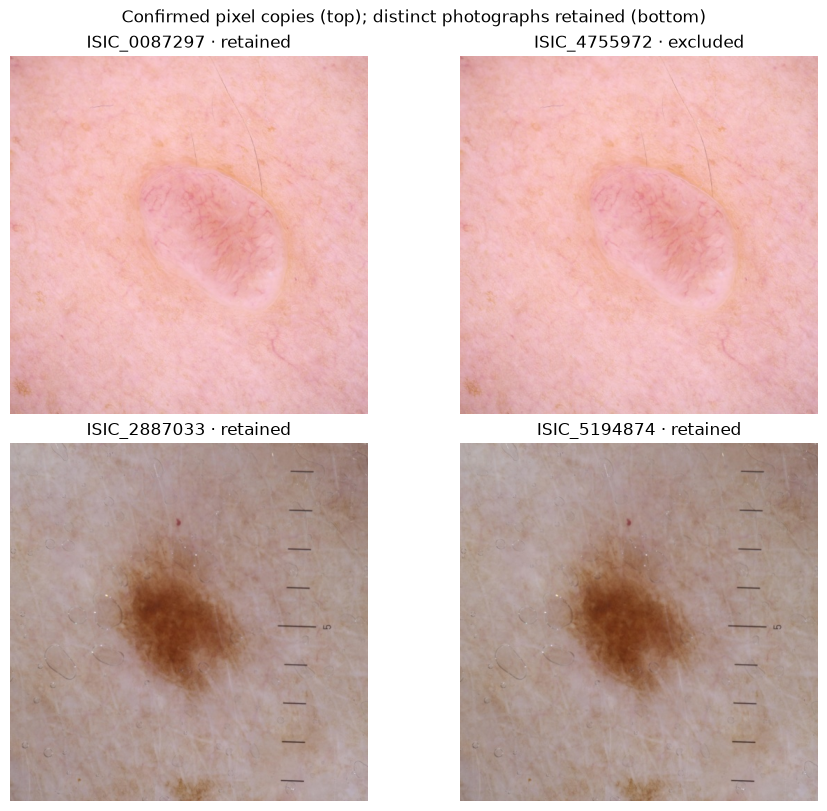

In [9]:
from PIL import Image as PILImage
exact = duplicates.sort_values("image_name").retained_image_name.iloc[0]
exact_ids = sorted(duplicates.loc[duplicates.retained_image_name.eq(exact), "image_name"])
distinct_ids = ["ISIC_2887033", "ISIC_5194874"]
assert set(distinct_ids).issubset(retained_ids)
figure, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
full_pixels = {}
for axis, image_id in zip(axes.flat, exact_ids + distinct_ids):
    with PILImage.open(DATA_DIR / "train" / (image_id + ".jpg")) as opened:
        pixels = np.asarray(opened.convert("RGB"))
    full_pixels[image_id] = pixels
    axis.imshow(pixels)
    row = ledger.set_index("image_name").loc[image_id]
    axis.set_title(image_id + " · " + row.decision)
    axis.axis("off")
figure.suptitle("Confirmed pixel copies (top); distinct photographs retained (bottom)")
finish_figure(figure, "exact_and_distinct_examples")
assert np.array_equal(full_pixels[exact_ids[0]], full_pixels[exact_ids[1]])
assert not np.array_equal(full_pixels[distinct_ids[0]], full_pixels[distinct_ids[1]])

## Read the manifest, partition and verification receipt

The retention ledger has one decision for every original development image. Retained and excluded IDs must be disjoint and together cover all 6,864 source IDs. The manifest records artifact hashes, the retention rule, pixel-fingerprint version and preserved patient memberships. Changing one of these files should fail verification rather than silently create a new population.

The cleaning receipt records the previous complete source and decoded-pixel checks. Reading a receipt is different from repeating the expensive image audit: the report verifies its dataset identity and shows its completion flags. Before-and-after fold counts make the effect of removing copies visible without rebuilding patient groups.

In [10]:
retained = ledger.loc[ledger.decision.eq("retained")]
assert set(retained.image_name).isdisjoint(set(excluded.image_name))
assert set(retained.image_name) | set(excluded.image_name) == original_ids
assert retained_ids == set(retained.image_name)
assert len(data) == 6706 and int(data.target.sum()) == 127
assert data.patient_id.nunique() == 422
assert data.loc[data.target.eq(1), "patient_id"].nunique() == 88
display(pd.DataFrame([{"manifest_sha256": dataset_identity["dataset_manifest_sha256"],
    "retention_rule": context["manifest"]["retention_rule"],
    "fingerprint_version": context["manifest"]["fingerprint_version"]}]))
display(context["fold_counts"])
receipt = read_json(ROOT / DIRECTORY / "cleaning/receipt.json")
assert receipt["dataset_identity"] == dataset_identity
display(pd.DataFrame([{key: receipt[key] for key in ["status", "sources_verified",
    "pixels_verified", "all_outer_and_preserved_inner_assignments_verified"]}]))
display(ledger[["width", "height"]].value_counts().rename("decoded_images").reset_index())

,manifest_sha256,retention_rule,fingerprint_version
0,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,lexicographically_smallest_image_name_per_conf...,sha256_str_dimensions_plus_decoded_rgb_v1


,fold,images_before,malignant_images_before,patients_before,images_after,malignant_images_after,patients_after,excluded_images,excluded_malignant
0,0,1370,25,84,1344,24,84,26,1
1,1,1372,26,84,1366,26,84,6,0
2,2,1381,26,87,1328,26,87,53,0
3,3,1371,25,82,1371,25,82,0,0
4,4,1370,26,85,1297,26,85,73,0


,status,sources_verified,pixels_verified,all_outer_and_preserved_inner_assignments_verified
0,complete,10,6864,True


,width,height,decoded_images
0,512,512,6864


## Preserve unusual metadata and document missing-site support

Unusual values are documented rather than guessed. A patient can have several recorded age buckets, possibly reflecting different visits or source errors; dates are unavailable, so replacing those ages with one inferred value would add an unsupported cleaning rule. In the retained records, 204 patients have several ages and 41 have an age span of at least 15 years.

Unknown site also has uneven patient, fold and label support. The table reports those counts so a later subgroup rate is read alongside its small malignant-patient denominator. The examples are deterministic inspection aids; they are not exclusions or new model features.

In [11]:
profiles = pd.read_csv(ROOT / "results/dedup_v1/audit/patient_profile_retained.csv")
display(profiles.loc[profiles.distinct_ages.gt(1)].sort_values(
    ["age_span", "patient_id"], ascending=[False, True]).head(12))
display(pd.DataFrame([{"patients_with_multiple_ages": int(profiles.distinct_ages.gt(1).sum()),
    "patients_age_span_at_least_15": int(profiles.age_span.ge(15).sum()),
    "unknown_site_patients": int(profiles.missing_site.gt(0).sum())}]))
show_saved_table("results/dedup_v1/audit/missing_site_by_fold_label_retained.csv")

,patient_id,images,malignant_images,fold,age_min,age_max,distinct_ages,missing_site,age_span
2,IP_0148558,35,0,0,35,55,5,0,20
27,IP_0843629,32,0,4,25,45,5,0,20
45,IP_1253185,36,0,3,25,45,5,0,20
51,IP_1512731,37,2,4,25,45,5,0,20
53,IP_1557123,15,0,2,25,45,2,0,20
81,IP_2166250,40,0,4,25,45,5,0,20
90,IP_2322991,31,0,3,45,65,5,0,20
111,IP_2738065,40,0,1,15,35,5,0,20
141,IP_3370847,29,0,1,25,45,5,0,20
165,IP_3846489,23,0,1,35,55,5,0,20


,patients_with_multiple_ages,patients_age_span_at_least_15,unknown_site_patients
0,204,41,53


,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


## Review image quality and the historical rotation without extra exclusions

**Added audit context; experiment scope unchanged.** Near-white area, low adjacent-pixel variation and dark borders identify review candidates only. They do not prove an image is unusable. This branch adds no quality or similarity exclusions beyond confirmed exact copies.

The transform sheet retains the historical weak rotation: nearest-neighbour interpolation, black fill and no expansion can create black corners or clip a lesion. This review documents that limitation while preserving the preparation recipe for replication. Revising interpolation, cropping or quality policy would be a separately declared experiment rather than a quiet change to the deduplicated population.

,angle_degrees,changes_to_historical_transform,expand,fill,interpretation,resize,rotation_interpolation
0,20,False,False,black,black corners and potential edge clipping need...,224,nearest


### Washed-out review candidates

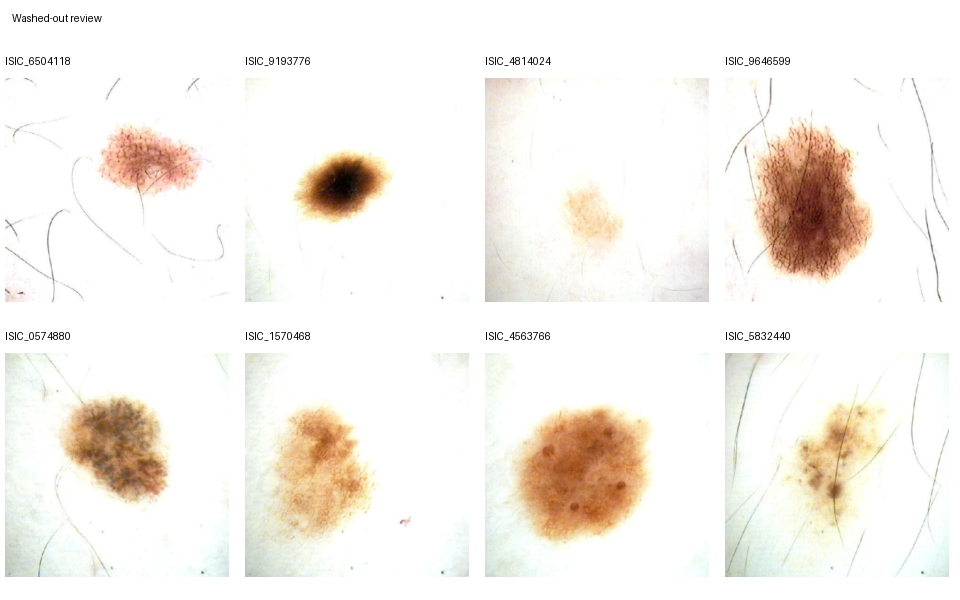

### Low-detail review candidates

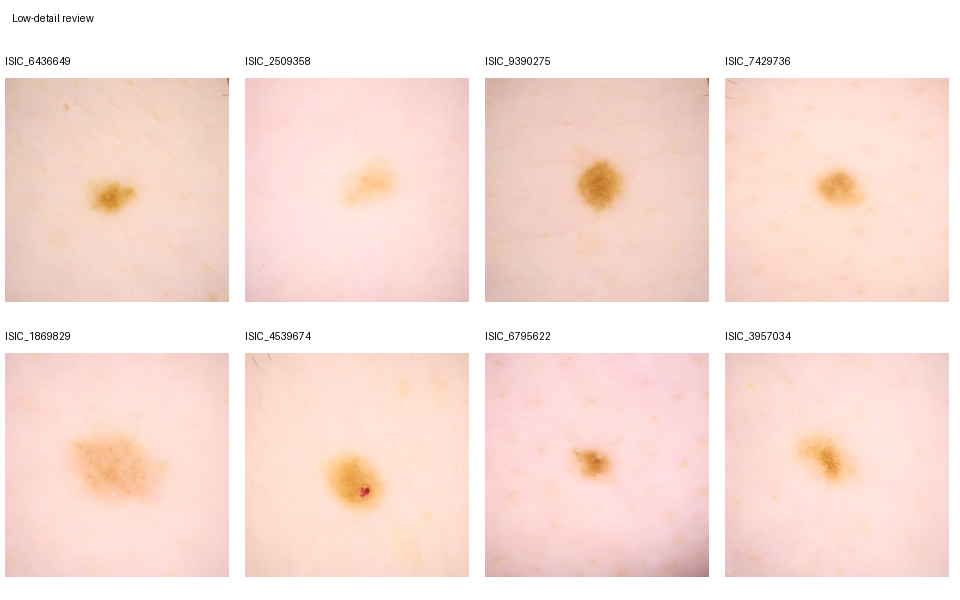

### Border-heavy review candidates

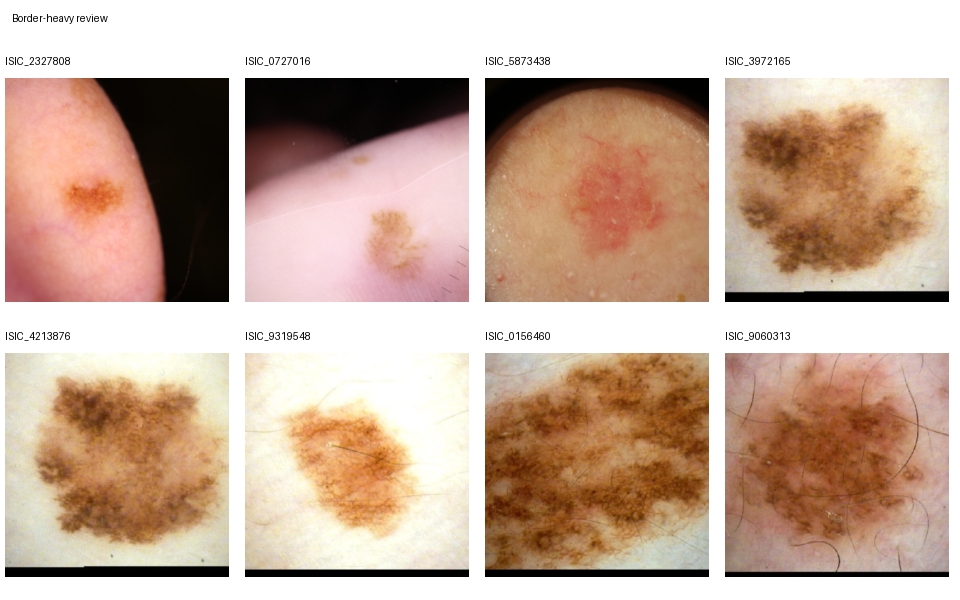

### Historical weak rotation

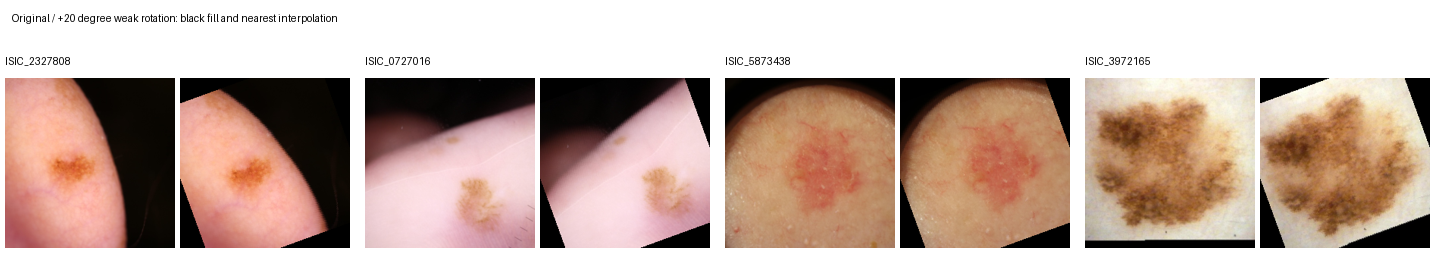

In [12]:
audit = read_json(ROOT / "results/dedup_v1/audit/audit_summary.json")
display(pd.DataFrame([audit["weak_rotation_review"]]))
for filename, title in [("near_white_fraction.png", "Washed-out review candidates"),
    ("gradient_proxy.png", "Low-detail review candidates"),
    ("near_black_border_fraction.png", "Border-heavy review candidates"),
    ("weak_rotation_review.png", "Historical weak rotation")]:
    display(Markdown("### " + title))
    display(Image(filename=str(ROOT / "results/dedup_v1/audit/figures" / filename)))

## Limitations

These checks can find missing fields, unexpected formats and some conflicting labels. They cannot confirm that the original age, sex, site or diagnosis was recorded correctly. An unknown category preserves a gap in the records, but cannot explain why the information is missing or remove any bias caused by that gap.

Five-year age buckets lose detail within each bucket. The metadata checks cannot inspect image contents or establish how well a future model will work. The separately documented audit above confirms exact decoded-pixel copies; it does not automatically remove visually similar but distinct photographs. No model is trained in this notebook, and the preparation checks do not provide a test-set performance result.

Exact-copy retention reduces repeated-observation weight but preserves every patient. It does not make multiple photographs from a patient independent. The reserved test remains outside this development report, including its identifiers and labels.

## Summary

The frozen clean run retains 6,706 images from 422 patients, with 127 malignant images and 88 patients who have a malignant image. The original development population had 6,864 images and 128 malignant images; the deterministic audit excludes 158 exact copies, including one malignant image. Every patient remains.

The same metadata rule represents missing model fields as `Unknown`; 195 retained sites are unknown, compared with 196 before retention. The record checks and frozen export agreement pass. Source files and historical outputs remain available, and no reserved-test records are loaded.

Next, [02_clean_data_eda.ipynb](02_clean_data_eda.ipynb) examines the retained training records and explains why images from one patient must stay together during evaluation. The audit details above show why the 158 exclusions are exact copies and how their provenance is preserved.